# Notebooks

<p class="subtitle">Jupyter notebooks as documentation pages</p>

This page is a Jupyter notebook ([`notebooks.ipynb`](https://github.com/webis-de/mkdocs-webis/blob/main/docs/notebooks.ipynb)), rendered as Markdown.
Thus, Markdown cells support the same extensions as other pages, e.g., citations [@fang2004formal].

## Code and Text Outputs

Code cells look like other code blocks, with prompts like in Jupyter.
Printed text and the cell's result are outputs:

In [1]:
axioms = ["TFC1", "TFC3", "LNC1"]
print(f"{len(axioms)} axioms: {', '.join(axioms)}")

3 axioms: TFC1, TFC3, LNC1


In [2]:
{axiom: len(axiom) for axiom in axioms}

{'TFC1': 4, 'TFC3': 4, 'LNC1': 4}

A cell can print text and return a result:

In [3]:
print("Counting characters...")
sum(len(axiom) for axiom in axioms)

Counting characters...


12

Logs and warnings (stderr) are not shown:

In [4]:
import warnings

warnings.warn("This warning is not shown.")
print("But this text is.")

But this text is.


/tmp/ipykernel_1130325/1617563220.py:3: UserWarning: This warning is not shown.
  warnings.warn("This warning is not shown.")


Errors show the traceback:

In [5]:
axioms.index("TFC2")

ValueError: 'TFC2' is not in list

## Magics and Shell Commands

In [6]:
%%time
sorted(axioms, key=len)

CPU times: user 5 μs, sys: 1 μs, total: 6 μs
Wall time: 7.87 μs


['TFC1', 'TFC3', 'LNC1']

In [7]:
!echo TFC1 TFC3 LNC1 | wc -w

3


## Data Frames

Data frames look like other tables:

In [8]:
from pandas import DataFrame

df = DataFrame({
    "axiom": axioms,
    "consistency": [0.62, 0.55, 0.58],
})
df

,axiom,consistency
0,TFC1,0.62
1,TFC3,0.55
2,LNC1,0.58


Also with a named index:

In [9]:
df.set_index("axiom")

,consistency
axiom,
TFC1,0.62
TFC3,0.55
LNC1,0.58


And with multiple index levels:

In [10]:
DataFrame({
    "group": ["term frequency", "term frequency", "length"],
    "axiom": axioms,
    "consistency": [0.62, 0.55, 0.58],
    "coverage": [0.31, 0.12, 0.44],
}).set_index(["group", "axiom"])

consistency  coverage
group          axiom                       
term frequency TFC1          0.62      0.31
               TFC3          0.55      0.12
length         LNC1          0.58      0.44

## Plots

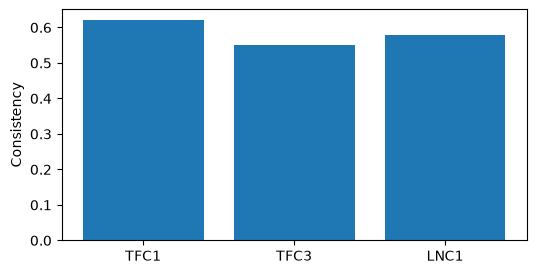

In [11]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(df["axiom"], df["consistency"])
ax.set_ylabel("Consistency")
plt.show()

Vector graphics:

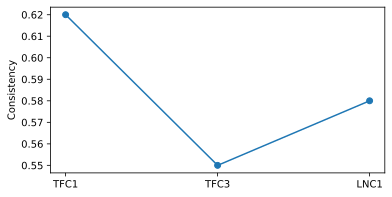

In [12]:
%config InlineBackend.figure_formats = ['svg']

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(df["axiom"], df["consistency"], marker="o")
ax.set_ylabel("Consistency")
plt.show()

## Maths

Markdown cells can contain maths, inline, like $tf(t, d)$, or as blocks:

$$
\mathrm{TFC1}: \quad tf(t, d_1) > tf(t, d_2) \Rightarrow s(q, d_1) > s(q, d_2)
$$

## Rich Outputs

In [13]:
from IPython.display import HTML, Markdown, Math, display

display(Markdown("Markdown output with **bold** text and a [link](https://webis.de/)."))
display(HTML("<p>HTML output with a <span class=\"badge\">badge</span>.</p>"))
display(Math(r"\mathrm{TFC1}: \quad tf(t, d_1) > tf(t, d_2) \Rightarrow s(q, d_1) > s(q, d_2)"))

Markdown output with **bold** text and a [link](https://webis.de/).

<IPython.core.display.Math object>

## Widgets

Progress bars:

In [14]:
from tqdm.auto import tqdm

for axiom in tqdm(axioms):
    pass

  0%|          | 0/3 [00:00<?, ?it/s]

Interactive widgets are shown as they were saved, but disabled:

In [15]:
from ipywidgets import IntSlider

IntSlider(value=3, min=1, max=10, description="Top k:")

IntSlider(value=3, description='Top k:', max=10, min=1)

In [16]:
from ipywidgets import Button, Checkbox, Dropdown, HBox, Text, ToggleButtons, VBox

VBox([
    Dropdown(options=["BM25", "TF-IDF", "QL"], value="BM25", description="Model:"),
    ToggleButtons(options=["Title", "Body", "Both"], value="Both"),
    Text(value="formal axioms", description="Query:"),
    HBox([Checkbox(value=True, description="Stemming"), Button(description="Search")]),
])

In [17]:
from ipywidgets import interact

@interact(k=(1, 3))
def top(k=2):
    return df.nlargest(k, "consistency")

interactive(children=(IntSlider(value=2, description='k', max=3, min=1), Output()), _dom_classes=('widget-inte…